In [1]:
import pandas as pd
import sys  
import os

sys.path.append('../')  # Add the parent directory to the system path to import custom modules
from src.Sql_pipeline_dataloader import load_cement_data  # Import the function to load cement data from the custom module
from src.metrics import print_metrics  # Import the function to print evaluation metrics from the custom module

In [2]:
df = load_cement_data()  # Load the cement consumption data into a DataFrame

In [3]:
import warnings
warnings.filterwarnings("ignore")  # Suppress warnings for cleaner output

In [4]:
site_id = 'SITE_001'  # Specify the site ID for which to filter the data
site_df = df[df['site_id'] == site_id].copy()  # Filter the DataFrame for the specified site ID and create a copy
site_df.index = pd.to_datetime(site_df.index)  # Ensure the index is in datetime format for time series analysis
site_df = site_df.set_index('date')  # Set the 'date' column as the index for time series analysis
site_df = site_df.sort_index()  # Sort the DataFrame by index (date) for proper time series analysis

In [5]:
site_df['lag_1'] = site_df['consumed_tonnes'].shift(1)  # Create a lag feature for the previous day's cement consumption
site_df['lag_3'] = site_df['consumed_tonnes'].shift(3)
site_df['lag_7'] = site_df['consumed_tonnes'].shift(7)

In [6]:
site_df['rolling_mean_3'] = site_df.groupby('site_id')['consumed_tonnes'].rolling(3).mean().reset_index(level=0, drop=True)  # Create a rolling mean feature with a window of 3 days)
site_df['rolling_std_7'] = site_df.groupby('site_id')['consumed_tonnes'].rolling(7).std().reset_index(level=0, drop=True)  # Create a rolling standard deviation feature with a window of 7 days

In [7]:
print(site_df.index)

DatetimeIndex(['2022-01-01', '2022-01-02', '2022-01-03', '2022-01-04',
               '2022-01-05', '2022-01-06', '2022-01-07', '2022-01-08',
               '2022-01-09', '2022-01-10',
               ...
               '2024-12-22', '2024-12-23', '2024-12-24', '2024-12-25',
               '2024-12-26', '2024-12-27', '2024-12-28', '2024-12-29',
               '2024-12-30', '2024-12-31'],
              dtype='datetime64[us]', name='date', length=1096, freq=None)


In [8]:
site_df['day_of_week'] = site_df.index.dayofweek  # Create a feature for the day of the week (0=Monday, 6=Sunday)
site_df['week_of_year'] = site_df.index.isocalendar().week  # Create a feature for the week of the year
site_df['month'] = site_df.index.month  # Create a feature for the month (1=January, 12=December)

In [9]:
site_df.columns

Index(['site_id', 'region', 'behavior', 'cement_type', 'planned_pour_tonnes',
       'consumed_tonnes', 'opening_inventory_tonnes', 'deliveries_tonnes',
       'closing_inventory_tonnes', 'rain_mm', 'avg_temp_c', 'silo_capacity',
       'lag_1', 'lag_3', 'lag_7', 'rolling_mean_3', 'rolling_std_7',
       'day_of_week', 'week_of_year', 'month'],
      dtype='str')

In [10]:
site_df['rain_x_pour'] = site_df['rain_mm'] * site_df['planned_pour_tonnes']  # Create an interaction feature between rain and pour
site_df['temp_x_pour'] = site_df['avg_temp_c'] * site_df['planned_pour_tonnes']  # Create an interaction feature between temperature and pour

In [11]:
site_df['behavior'].value_counts()  # Check the distribution of the 'behavior' column to understand the target variable's classes


behavior
aggressive    1096
Name: count, dtype: int64

In [12]:
df['behavior'].value_counts()  # Check the distribution of the 'behavior' column in the original DataFrame to understand the target variable's classes across all sites

behavior
aggressive      15344
conservative     9864
chaotic          7672
Name: count, dtype: int64

In [13]:
site_df['inventory_gap'] = site_df['opening_inventory_tonnes'] + site_df['deliveries_tonnes'] - site_df['planned_pour_tonnes']  # Create a feature for the inventory gap, which is the difference between available inventory and planned pour

In [14]:
import numpy as np
site_df['inventory_ratio'] = np.where(
    site_df['silo_capacity'] > 0, 
    site_df['opening_inventory_tonnes'] / site_df['silo_capacity'], 
    np.nan 
)                   # Create a feature for the inventory ratio, which is the ratio of inventory gap to planned pour, handling division by zero

In [15]:
site_df.isnull().sum()  # Check for any missing values in the DataFrame to ensure data quality before modeling

site_id                     0
region                      0
behavior                    0
cement_type                 0
planned_pour_tonnes         0
consumed_tonnes             0
opening_inventory_tonnes    0
deliveries_tonnes           0
closing_inventory_tonnes    0
rain_mm                     0
avg_temp_c                  0
silo_capacity               0
lag_1                       1
lag_3                       3
lag_7                       7
rolling_mean_3              2
rolling_std_7               6
day_of_week                 0
week_of_year                0
month                       0
rain_x_pour                 0
temp_x_pour                 0
inventory_gap               0
inventory_ratio             0
dtype: int64

In [16]:
site_df.dropna(inplace=True)  # Drop rows with any missing values to prepare the data for modeling

In [17]:
site_df.head()  # Display the first few rows of the DataFrame to verify the features and data integrity

,site_id,region,behavior,cement_type,planned_pour_tonnes,consumed_tonnes,opening_inventory_tonnes,deliveries_tonnes,closing_inventory_tonnes,rain_mm,...,lag_7,rolling_mean_3,rolling_std_7,day_of_week,week_of_year,month,rain_x_pour,temp_x_pour,inventory_gap,inventory_ratio
date,,,,,,,,,,,,,,,,,,,,,
2022-01-08,SITE_001,North,aggressive,CEM_I,42.12,34.28,14.12,20.16,0.00,1.95,...,34.54,30.023333,8.383131,5,1,1,82.1340,1091.7504,-7.84,0.031518
2022-01-09,SITE_001,North,aggressive,CEM_I,0.00,0.00,0.00,34.38,34.38,1.42,...,45.26,22.626667,15.099577,6,1,1,0.0000,0.0000,34.38,0.000000
2022-01-10,SITE_001,North,aggressive,CEM_II,30.99,30.99,34.38,35.37,38.76,3.49,...,38.69,21.756667,14.621270,0,2,1,108.1551,513.5043,38.76,0.076741
2022-01-11,SITE_001,North,aggressive,CEM_II,37.26,29.81,38.76,40.46,49.41,5.71,...,33.16,20.266667,14.507304,1,2,1,212.7546,-29.0628,41.96,0.086518
2022-01-12,SITE_001,North,aggressive,CEM_III,54.09,54.09,49.41,49.34,44.66,1.36,...,47.04,38.296667,16.176063,2,2,1,73.5624,1042.8552,44.66,0.110290


In [18]:
site_df.columns

Index(['site_id', 'region', 'behavior', 'cement_type', 'planned_pour_tonnes',
       'consumed_tonnes', 'opening_inventory_tonnes', 'deliveries_tonnes',
       'closing_inventory_tonnes', 'rain_mm', 'avg_temp_c', 'silo_capacity',
       'lag_1', 'lag_3', 'lag_7', 'rolling_mean_3', 'rolling_std_7',
       'day_of_week', 'week_of_year', 'month', 'rain_x_pour', 'temp_x_pour',
       'inventory_gap', 'inventory_ratio'],
      dtype='str')

In [19]:
features =['planned_pour_tonnes', 'rain_mm', 'avg_temp_c',
       'lag_1', 'lag_3', 'lag_7', 'rolling_mean_3', 'rolling_std_7',
       'day_of_week', 'week_of_year', 'month', 'rain_x_pour', 'temp_x_pour',
       'inventory_gap', 'inventory_ratio']

In [20]:
X = site_df[features]
Y = site_df['consumed_tonnes']

In [21]:
split_index = int(len(site_df) * 0.8)
X_train, X_test = X.iloc[:split_index], X.iloc[split_index:] 
y_train, y_test = Y.iloc[:split_index], Y.iloc[split_index:]    

In [22]:
from sklearn.ensemble import RandomForestRegressor

In [23]:
rf = RandomForestRegressor(
    n_estimators=200,
    random_state=30,
    max_depth = 10
)
rf.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"criterion criterion: {""squared_error"", ""absolute_error"", ""friedman_mse"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""friedman_mse"", which usesmean squared error with Friedman's improvement score for potentialsplits, ""absolute_error"" for the mean absolute error, which minimizesthe L1 loss using the median of each terminal node, and ""poisson"" whichuses reduction in Poisson deviance to find splits.Training using ""absolute_error"" is significantly slowerthan when using ""squared_error""... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",10
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples 

In [24]:
rf_forecast = rf.predict(X_test)

In [25]:
print_metrics(y_test, rf_forecast, 'Random Forest Engineered')

Random Forest Engineered - MAPE: 4.89%, RMSE: 1.81 tonnes


In [26]:
import plotly.graph_objects as go

fig = go.Figure()

fig.add_trace(go.Scatter(  # Add the actual values of the target variable to the plot
    x=y_test.index, 
    y=y_test, 
    mode='lines', 
    name='Actual T',
    line=dict(color='black')  
))   

fig.add_trace(go.Scatter( # Add the Random Forest forecasted values to the plot
    x=y_test.index,
    y=rf_forecast,
    mode='lines',
    name='Random Forest Forecast',
    line=dict(color='red')
))

fig.update_layout(             # Update the layout of the plot
    title=f'Random Forest Model Forecast vs Actual - {site_df} Engineered', 
    xaxis_title='Date', 
    yaxis_title='Cement Consumed Tonnes',
    legend=dict(x=0, y=1),
    template='plotly_white',
    width=1000, 
    height=450
)

fig.show()

<Axes: title={'center': 'Feature Importance - Random Forest Engineered'}>

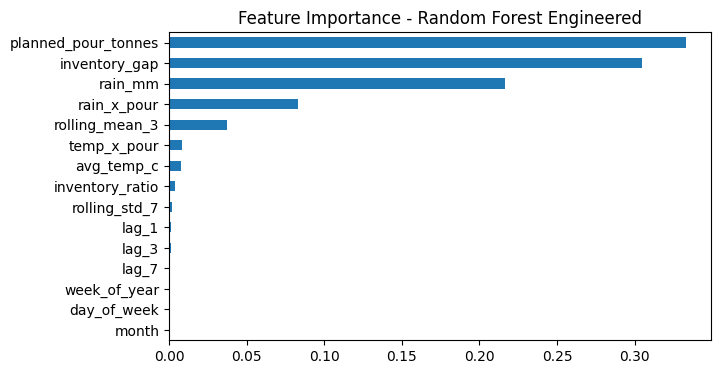

In [27]:
importance = pd.Series(rf.feature_importances_, index=features).sort_values()
importance.plot(kind='barh', figsize=(7,4), title='Feature Importance - Random Forest Engineered')

## INVENTORY SIMULATION

In [28]:
site_df['silo_capacity'].head(1)

date
2022-01-08    448
Name: silo_capacity, dtype: int64

In [29]:
silo_capacity = 448
initial_inventory = 270
reorder_threshold = 0.2 * silo_capacity
target_inventory = 0.8 * silo_capacity
lead_time_days = 2

buffer_rain_threshold = 10 #mm
buffer_increase = 0.1


In [30]:
df_sim = pd.DataFrame({
    'date': X_test.index,
    'forecasted_consumption': rf_forecast,
    'rain_forecast_mm': X_test['rain_mm'].values
})

In [31]:
df_sim.head

<bound method NDFrame.head of           date  forecasted_consumption  rain_forecast_mm
0   2024-05-28                0.151195              0.69
1   2024-05-29               39.527141              2.36
2   2024-05-30               33.735808              0.99
3   2024-05-31               12.810636              0.67
4   2024-06-01               27.552365              0.11
..         ...                     ...               ...
213 2024-12-27               24.592518             11.92
214 2024-12-28               22.569662              9.21
215 2024-12-29               31.768439              5.53
216 2024-12-30                0.132950             17.63
217 2024-12-31               51.423261              3.49

[218 rows x 3 columns]>

In [32]:
df_sim['sim_inventory'] = np.nan
df_sim['reorder_flag'] = False
df_sim['recommended_delivery_date'] = None
df_sim['recommended_delivery_quantity'] = 0.0
df_sim['buffer_applied'] =False

In [33]:
#simulation loop

inventory = initial_inventory
delivery_queue = {}

for i, row, in df_sim.iterrows():
    today = row['date']

    if today in delivery_queue:
        inventory += delivery_queue[today]
        inventory = min(inventory, silo_capacity)

    consumption = row['forecasted_consumption']
    inventory -= consumption

    df_sim.loc[i, 'sim_inventory'] = inventory

    if inventory < reorder_threshold:
        df_sim.loc[i, 'reorder_flag'] = True
        delivery_date = today + pd.Timedelta(days=lead_time_days)

        delivery_qty = target_inventory - inventory
        if row['rain_forecast_mm'] > buffer_rain_threshold:
            delivery_qty *= (1 + buffer_increase)
            df_sim.loc[i, 'buffer_applied'] = True

        delivery_qty = min(delivery_qty, silo_capacity - inventory)
        delivery_queue[delivery_date] = delivery_qty

        df_sim.loc[i, 'recommended_delivery_date'] = delivery_date.strftime('%y-%m-%d')
        df_sim.loc[i, 'recommended_delivery_quantity'] = round(delivery_qty, 2)


In [34]:
stockouts = (df_sim['sim_inventory'] <= 0).sum()
service_level = 100 * (1 - stockouts / len(df_sim))
num_deliveries = (df_sim['reorder_flag']).sum()

In [35]:
stockouts

np.int64(3)

In [36]:
service_level

np.float64(98.62385321100918)

In [37]:
num_deliveries

np.int64(28)

In [38]:
df_sim.head()

,date,forecasted_consumption,rain_forecast_mm,sim_inventory,reorder_flag,recommended_delivery_date,recommended_delivery_quantity,buffer_applied
0,2024-05-28,0.151195,0.69,269.848805,False,None,0.0,False
1,2024-05-29,39.527141,2.36,230.321664,False,None,0.0,False
2,2024-05-30,33.735808,0.99,196.585857,False,None,0.0,False
3,2024-05-31,12.810636,0.67,183.775220,False,None,0.0,False
4,2024-06-01,27.552365,0.11,156.222856,False,None,0.0,False
